# Week 5 · Stock Health, Overstock/Understock & Inventory Ageing
**CadetX — Heavy Supplier, Inventory & Warehouse Analytics · Phase 2 (Core Product, Inventory & Warehouse Analytics)**

Tasks covered this sprint (Task Catalogue, section B):
1. Stock Health Assessment
2. Overstock & Understock Detection
3. Inventory Aging Analysis
4. Replenishment behaviour (supports the above) and stock value

**Ground rules** (carried over from Weeks 1–4):
- Demand = **Delivered** sales orders from `sales_transactions.csv`, last 12 months (to 2024-12-31).
- Stock = `inventory_position.csv` `current_stock`, taken as recorded; value = `current_stock × unit_cost`.
- Stock history = `stock_ledger.csv`, using `implied_signed_quantity` (the Week 3 fix for the ADJUSTMENT sign problem).
- All 180 positions carry the Week 3 `scale_mismatch_flag`: `current_stock` is far above `max_stock`. Results are **as recorded**; the ledger is used to show how the stock built up.

In [ ]:
# Mount Google Drive (Colab). Approve the pop-up the first time you run this cell.
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
BLUE, ORANGE, GREY, RED = "#1f3a93", "#e8743b", "#8a8f98", "#d64545"

# Real Drive locations (corrected copies; the old/ folders hold the uncorrected September files)
BASE = Path("/content/drive/MyDrive/Cadex/HEAVY_SUPPLIERS_WAREHOUSE PROJECT")
SRC = {
    "sales_transactions.csv": BASE / "week-02" / "week-02",
    "inventory_position.csv": BASE / "week-02" / "week-02",
    "stock_ledger.csv": BASE / "week-3",
}

# Link the CSVs into one local folder so the loading code below stays unchanged (no big copies)
DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
for name, folder in SRC.items():
    target = folder / name
    if not target.exists():
        raise FileNotFoundError(f"Not found in Drive: {target}  (is Drive mounted? check the folder path)")
    link = DATA_DIR / name
    if link.is_symlink() or link.exists():
        link.unlink()
    link.symlink_to(target)

OUT_DIR = BASE / "week-05" / "week-05" / "outputs"
(OUT_DIR / "charts").mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / f"{name}.png", bbox_inches="tight")

## 1. Load data

In [2]:
sales = pd.read_csv(DATA_DIR / "sales_transactions.csv", usecols=["so_id", "product_id", "quantity", "order_status", "order_date", "branch_id"],
                    parse_dates=["order_date"])
d = sales[sales.order_status == "Delivered"]
SALES_END = d.order_date.max()
led = pd.read_csv(DATA_DIR / "stock_ledger.csv", parse_dates=["movement_date"]).sort_values(["product_id", "branch_id", "movement_date", "movement_id"])
inv = pd.read_csv(DATA_DIR / "inventory_position.csv")
AS_OF = led.movement_date.max()
KEY = ["product_id", "branch_id"]

print(f"Positions (product x branch): {len(inv)}   products: {inv.product_id.nunique()}   branches: {inv.branch_id.nunique()}")
print(f"Sales to {SALES_END.date()}; stock ledger {led.movement_date.min().date()} to {AS_OF.date()} ({len(led):,} movements)")
print("Ledger movements:", led.movement_type.value_counts().to_dict())

Positions (product x branch): 180   products: 30   branches: 6
Sales to 2024-12-31; stock ledger 2019-01-01 to 2025-01-28 (237,230 movements)
Ledger movements: {'IN': 127611, 'OUT': 107165, 'ADJUSTMENT': 2454}

## 2. Stock Health Assessment
Each of the 180 product-branch positions is compared with its own safety stock, reorder level and maximum stock:

| Status | Rule |
|---|---|
| Stockout risk | stock below safety stock |
| Below reorder | stock below reorder level |
| Healthy | between reorder level and max stock |
| Overstock | up to 2x max stock |
| Heavy overstock | 2x to 10x max stock |
| Critical overstock | more than 10x max stock |

In [3]:
L12 = d[d.order_date > SALES_END - pd.Timedelta(days=365)]
pos = inv[["product_id", "product_name", "category", "branch_id", "branch_name", "opening_stock", "safety_stock", "reorder_level",
           "max_stock", "current_stock", "unit_cost", "lead_time_days", "criticality_level"]].copy()
pos = pos.merge(L12.groupby(KEY).quantity.sum().rename("units_L12M").reset_index(), on=KEY, how="left").fillna({"units_L12M": 0})
pos["daily_demand"] = pos.units_L12M / 365
pos["stock_value"] = pos.current_stock * pos.unit_cost
pos["stock_to_max"] = pos.current_stock / pos.max_stock
pos["days_of_cover"] = pos.current_stock / pos.daily_demand
pos["max_stock_days"] = pos.max_stock / pos.daily_demand

pos["status"] = np.select(
    [pos.current_stock < pos.safety_stock, pos.current_stock < pos.reorder_level, pos.current_stock <= pos.max_stock,
     pos.current_stock <= 2 * pos.max_stock, pos.current_stock <= 10 * pos.max_stock],
    ["Stockout risk", "Below reorder", "Healthy", "Overstock", "Heavy overstock"], "Critical overstock")
order = ["Stockout risk", "Below reorder", "Healthy", "Overstock", "Heavy overstock", "Critical overstock"]
st = pos.status.value_counts().reindex(order, fill_value=0)
print(st.to_string())
print(f"\nStock vs max stock: median {pos.stock_to_max.median():.0f}x, range {pos.stock_to_max.min():.0f}x to {pos.stock_to_max.max():.0f}x; network {pos.current_stock.sum()/pos.max_stock.sum():.1f}x")
print(f"Median days of cover: {pos.days_of_cover.median():,.0f} days ({pos.days_of_cover.median()/365:.0f} years).  Max stock itself equals a median {pos.max_stock_days.median():.0f} days of demand.")

status
Stockout risk           0
Below reorder           0
Healthy                 0
Overstock               0
Heavy overstock         0
Critical overstock    180

Stock vs max stock: median 349x, range 177x to 854x; network 333.3x
Median days of cover: 35,689 days (98 years).  Max stock itself equals a median 102 days of demand.

In [4]:
# Is the reorder level itself sensible? Required reorder point = demand during lead time + safety stock.
pos["required_reorder_point"] = pos.daily_demand * pos.lead_time_days + pos.safety_stock
low = (pos.reorder_level < pos.required_reorder_point)
print(f"Positions whose recorded reorder level is below demand-during-lead-time + safety stock: {low.sum()} of {len(pos)}")
print(pos[["reorder_level", "required_reorder_point"]].describe().round(1).loc[["mean", "min", "max"]].to_string())

Positions whose recorded reorder level is below demand-during-lead-time + safety stock: 161 of 180
      reorder_level  required_reorder_point
mean           64.6                    96.4
min            24.0                    33.2
max           119.0                   226.4

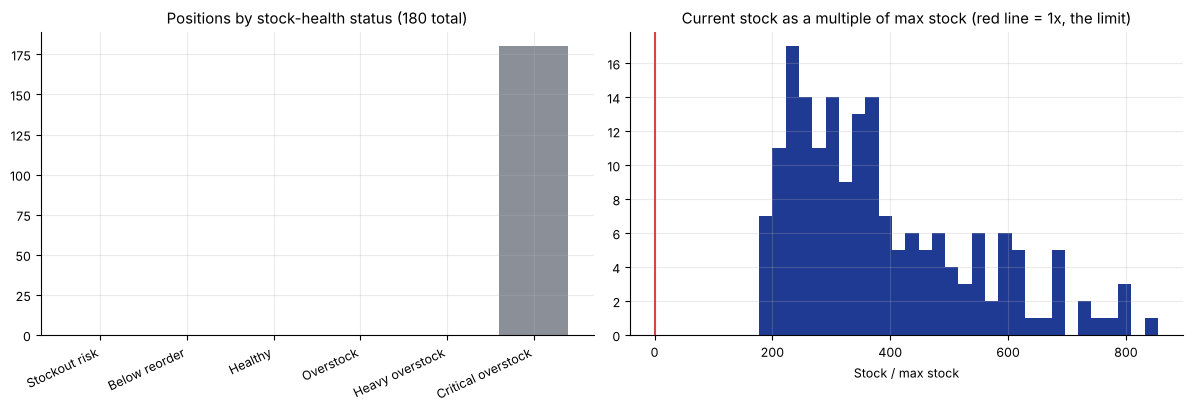

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(order, st.values, color=[RED, RED, BLUE, ORANGE, ORANGE, GREY])
ax[0].set_title("Positions by stock-health status (180 total)"); plt.setp(ax[0].get_xticklabels(), rotation=25, ha="right")
ax[1].hist(pos.stock_to_max, bins=30, color=BLUE); ax[1].axvline(1, c=RED, lw=1.5)
ax[1].set_title("Current stock as a multiple of max stock (red line = 1x, the limit)"); ax[1].set_xlabel("Stock / max stock")
save("01_stock_health")

## 3. Overstock & Understock Detection
**Overstock** = units above max stock (and their value at unit cost). **Understock** is checked two ways: today (stock below reorder or safety), and in history (any ledger point where the running balance fell below reorder level or reached zero).

In [6]:
pos["excess_units"] = (pos.current_stock - pos.max_stock).clip(lower=0)
pos["excess_value"] = pos.excess_units * pos.unit_cost
pos["years_to_sell_excess"] = pos.excess_units / pos.units_L12M

tot_val, exc_val = pos.stock_value.sum(), pos.excess_value.sum()
print(f"Stock value: INR {tot_val/1e7:,.0f} cr.  Value above max stock: INR {exc_val/1e7:,.0f} cr ({exc_val/tot_val*100:.1f}% of all stock value)")
print(f"Units above max stock: {pos.excess_units.sum():,.0f} of {pos.current_stock.sum():,.0f}")
print(f"At the last-12-month sales rate, the excess takes {pos.excess_units.sum()/pos.units_L12M.sum():.0f} years to sell")
print(f"Understock today (below reorder or safety): {int((pos.status.isin(['Stockout risk', 'Below reorder'])).sum())} positions")

Stock value: INR 28,129 cr.  Value above max stock: INR 28,046 cr (99.7% of all stock value)
Units above max stock: 19,245,350 of 19,303,266
At the last-12-month sales rate, the excess takes 97 years to sell
Understock today (below reorder or safety): 0 positions

In [7]:
cat = pos.groupby("category").agg(stock_value_cr=("stock_value", lambda s: s.sum() / 1e7), excess_value_cr=("excess_value", lambda s: s.sum() / 1e7),
                                  excess_units=("excess_units", "sum")).sort_values("excess_value_cr", ascending=False)
br = pos.groupby("branch_name").agg(stock_value_cr=("stock_value", lambda s: s.sum() / 1e7), excess_value_cr=("excess_value", lambda s: s.sum() / 1e7),
                                    stock_to_max=("current_stock", "sum")).assign(stock_to_max=lambda x: x.stock_to_max / pos.groupby("branch_name").max_stock.sum())
print(cat.round(0).head(6).to_string()); print(); print(br.round(1).to_string())

               stock_value_cr  excess_value_cr  excess_units
category                                                    
Engine                 9407.0           9381.0       2577748
Hydraulic              7698.0           7673.0       3838521
Transmission           4532.0           4519.0        659745
Undercarriage          3704.0           3693.0       2599215
Electrical             1374.0           1370.0       1897586
Cooling                 494.0            493.0        632228

                     stock_value_cr  excess_value_cr  stock_to_max
branch_name                                                       
Ahmedabad West Hub           4613.0           4600.4         325.6
Chennai South Hub            4779.8           4765.4         335.4
Delhi Central                4770.9           4756.4         337.5
Hyderabad Logistics          4722.5           4709.2         343.9
Kolkata East Depot           4470.3           4452.7         288.0
Pune Distribution            4772.8       

In [8]:
top = pos.sort_values("excess_value", ascending=False).head(10)
top[["product_name", "branch_name", "current_stock", "max_stock", "stock_to_max", "excess_value", "years_to_sell_excess"]].assign(
    excess_value_cr=lambda x: x.excess_value / 1e7).drop(columns="excess_value").round({"stock_to_max": 0, "years_to_sell_excess": 0, "excess_value_cr": 0})

,product_name,branch_name,current_stock,max_stock,stock_to_max,years_to_sell_excess,excess_value_cr
86,Engine Block EB-600,Chennai South Hub,113851,370,308.0,95.0,1084.0
87,Engine Block EB-600,Hyderabad Logistics,110035,226,487.0,109.0,1049.0
85,Engine Block EB-600,Pune Distribution,106048,210,505.0,141.0,1011.0
89,Engine Block EB-600,Ahmedabad West Hub,105135,131,803.0,98.0,1003.0
84,Engine Block EB-600,Delhi Central,100967,387,261.0,104.0,961.0
88,Engine Block EB-600,Kolkata East Depot,96547,508,190.0,72.0,917.0
80,Transmission Assembly TA-800,Chennai South Hub,114302,303,377.0,80.0,781.0
79,Transmission Assembly TA-800,Pune Distribution,113386,164,691.0,101.0,776.0
81,Transmission Assembly TA-800,Hyderabad Logistics,111315,377,295.0,114.0,760.0
78,Transmission Assembly TA-800,Delhi Central,111321,384,290.0,114.0,760.0


In [9]:
# Historical understock: any point where the ledger balance fell below reorder level (or to zero)
h = led.merge(pos[KEY + ["product_name", "branch_name", "safety_stock", "reorder_level", "max_stock"]], on=KEY)
low_ev = h[h.running_balance < h.reorder_level][["movement_date", "product_name", "branch_name", "movement_type", "running_balance", "safety_stock", "reorder_level"]]
print(f"Ledger points below reorder level: {len(low_ev)}, in {low_ev.groupby(['product_name','branch_name']).ngroups} positions; last one on {low_ev.movement_date.max().date()}")
print(f"Ledger points with zero or negative balance: {(h.running_balance <= 0).sum()}  (lowest balance anywhere: {h.running_balance.min()})")
first_over = h[h.running_balance > h.max_stock].groupby(KEY).movement_date.min()
print(f"Positions that went above max stock: {len(first_over)} of {len(pos)}; all by {first_over.max().date()}; median {first_over.median().date()}")
low_ev

Ledger points below reorder level: 5, in 3 positions; last one on 2019-01-17
Ledger points with zero or negative balance: 0  (lowest balance anywhere: 14)
Positions that went above max stock: 180 of 180; all by 2019-02-22; median 2019-01-21

,movement_date,product_name,branch_name,movement_type,running_balance,safety_stock,reorder_level
32963,2019-01-16,Fuel Injector FI-220,Chennai South Hub,ADJUSTMENT,62,40,68
178269,2019-01-09,Idler Wheel IW-55,Hyderabad Logistics,OUT,28,16,31
178270,2019-01-12,Idler Wheel IW-55,Hyderabad Logistics,OUT,22,16,31
207063,2019-01-15,O-Ring Set OR-50,Chennai South Hub,OUT,25,19,33
207064,2019-01-17,O-Ring Set OR-50,Chennai South Hub,OUT,14,19,33


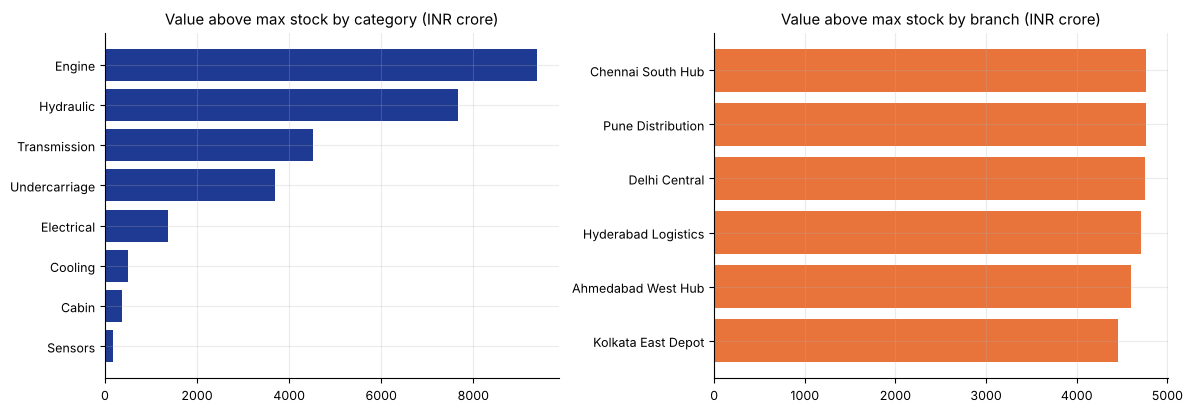

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
c = cat.head(8).sort_values("excess_value_cr")
ax[0].barh(c.index, c.excess_value_cr, color=BLUE); ax[0].set_title("Value above max stock by category (INR crore)")
b = br.sort_values("excess_value_cr")
ax[1].barh(b.index, b.excess_value_cr, color=ORANGE); ax[1].set_title("Value above max stock by branch (INR crore)")
save("02_excess_value")

## 4. Inventory Aging Analysis
Age of stock on hand at the end of the ledger, built with **FIFO** (first in, first out): stock arrives in layers (the opening balance, each purchase receipt, each positive adjustment) and all outflows (sales and negative adjustments) consume the oldest layers first. What remains is the stock on hand, each layer dated by its arrival.
FIFO is an assumption about how stock is picked; a physical stock-age check would settle it.

In [11]:
sg = led.implied_signed_quantity
opening = inv[KEY + ["opening_stock"]].rename(columns={"opening_stock": "qty"}).assign(date=led.movement_date.min())
inflow = led[sg > 0][KEY + ["movement_date", "implied_signed_quantity"]].rename(columns={"movement_date": "date", "implied_signed_quantity": "qty"})
layers = pd.concat([opening, inflow]).sort_values(KEY + ["date"], kind="stable").reset_index(drop=True)
outflow = (-led[sg < 0].groupby(KEY).implied_signed_quantity.sum()).rename("out")
layers = layers.merge(outflow.reset_index(), on=KEY, how="left").fillna({"out": 0})
layers["cum_in"] = layers.groupby(KEY).qty.cumsum()
layers["remaining"] = np.minimum(layers.qty, layers.cum_in - layers.out).clip(lower=0)
layers["age_days"] = (AS_OF - layers.date).dt.days

# Tie-out: remaining stock per position must equal the last ledger balance
end_bal = led.groupby(KEY).tail(1).set_index(KEY).running_balance
chk = layers.groupby(KEY).remaining.sum().to_frame("fifo").join(end_bal).join(inv.set_index(KEY).current_stock)
print(f"FIFO stock equals last ledger balance in {(chk.fifo == chk.running_balance).sum()} of {len(chk)} positions;"
      f" equals current_stock in {(chk.fifo == chk.current_stock).sum()}")
print(f"Total: FIFO {chk.fifo.sum():,.0f}   ledger end {chk.running_balance.sum():,.0f}   current_stock {chk.current_stock.sum():,.0f}")

FIFO stock equals last ledger balance in 174 of 180 positions; equals current_stock in 166
Total: FIFO 19,305,994   ledger end 19,304,792   current_stock 19,303,266

In [12]:
bins = [-1, 90, 180, 365, 730, 1095, 10**6]
labels = ["0-90 days", "91-180 days", "181-365 days", "1-2 years", "2-3 years", "3+ years"]
layers["bucket"] = pd.cut(layers.age_days, bins, labels=labels)
layers = layers.merge(inv[KEY + ["unit_cost", "product_name", "branch_name", "category"]], on=KEY)
layers["value"] = layers.remaining * layers.unit_cost

ag = layers.groupby("bucket", observed=False).agg(units=("remaining", "sum"), value=("value", "sum"))
ag["units_pct"] = ag.units / ag.units.sum() * 100; ag["value_cr"] = ag.value / 1e7; ag["value_pct"] = ag.value / ag.value.sum() * 100
print(ag[["units", "units_pct", "value_cr", "value_pct"]].round(1).to_string())
w_age = (layers.remaining * layers.age_days).sum() / layers.remaining.sum()
print(f"\nWeighted average age of stock: {w_age:,.0f} days ({w_age/365:.1f} years).  Older than 2 years: {ag.units_pct.loc[['2-3 years','3+ years']].sum():.1f}% of units")

                units  units_pct  value_cr  value_pct
bucket                                               
0-90 days      759712        3.9    1113.7        4.0
91-180 days    819570        4.2    1157.3        4.1
181-365 days  1656722        8.6    2445.5        8.7
1-2 years     3439062       17.8    5051.4       18.0
2-3 years     3373309       17.5    4845.5       17.2
3+ years      9257619       48.0   13518.9       48.1

Weighted average age of stock: 1,049 days (2.9 years).  Older than 2 years: 65.4% of units

In [13]:
by_branch = layers.pivot_table(index="branch_name", columns="bucket", values="remaining", aggfunc="sum", observed=False)
by_branch_pct = by_branch.div(by_branch.sum(axis=1), axis=0) * 100
by_prod = layers.groupby(["product_id", "product_name"]).apply(lambda g: pd.Series({
    "stock_units": g.remaining.sum(), "avg_age_days": (g.remaining * g.age_days).sum() / g.remaining.sum(),
    "pct_over_2y": g.loc[g.age_days > 730, "remaining"].sum() / g.remaining.sum() * 100}), include_groups=False).reset_index()
print(by_branch_pct.round(1).to_string())
print(f"\nProduct average age: {by_prod.avg_age_days.min():.0f} to {by_prod.avg_age_days.max():.0f} days; share over 2 years: {by_prod.pct_over_2y.min():.0f}% to {by_prod.pct_over_2y.max():.0f}%")

bucket               0-90 days  91-180 days  181-365 days  1-2 years  2-3 years  3+ years
branch_name                                                                              
Ahmedabad West Hub         4.3          4.2           8.8       17.1       16.6      49.0
Chennai South Hub          4.1          4.5           8.7       18.4       18.2      46.1
Delhi Central              4.0          4.2           8.9       17.5       18.8      46.6
Hyderabad Logistics        3.4          4.6           8.4       17.9       16.3      49.4
Kolkata East Depot         4.2          3.8           8.2       18.2       18.4      47.2
Pune Distribution          3.7          4.2           8.4       17.7       16.5      49.5

Product average age: 1023 to 1073 days; share over 2 years: 64% to 67%

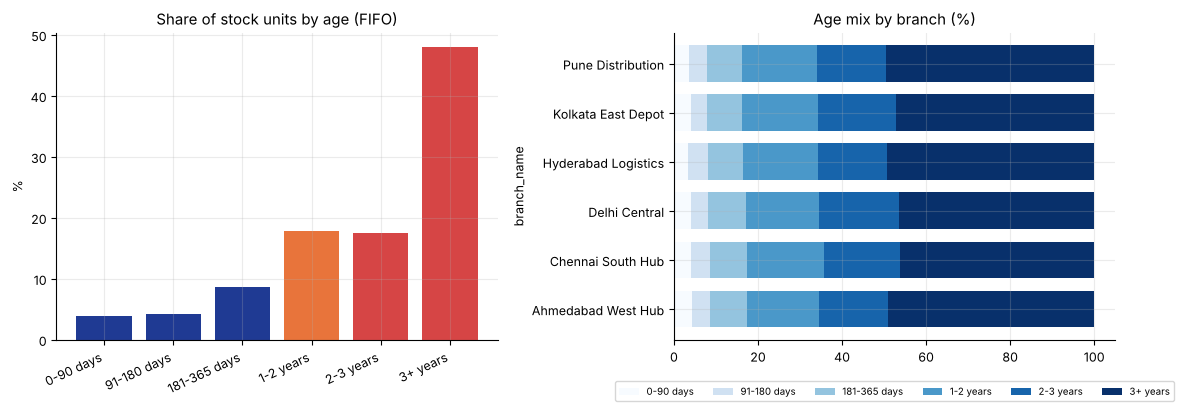

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(labels, ag.units_pct, color=[BLUE, BLUE, BLUE, ORANGE, RED, RED]); ax[0].set_title("Share of stock units by age (FIFO)"); ax[0].set_ylabel("%")
plt.setp(ax[0].get_xticklabels(), rotation=25, ha="right")
by_branch_pct.plot(kind="barh", stacked=True, ax=ax[1], colormap="Blues", width=.75); ax[1].set_title("Age mix by branch (%)"); ax[1].legend(fontsize=7, ncol=6, loc="upper center", bbox_to_anchor=(.5, -.12))
save("03_ageing")

## 5. Replenishment behaviour
For every purchase receipt in the ledger, the stock level **just before it arrived** is compared with the position's reorder level and max stock. A sound policy receives stock when it is at or below the reorder level.

In [15]:
r = led.merge(pos[KEY + ["reorder_level", "safety_stock", "max_stock"]], on=KEY)
r["pre_stock"] = r.running_balance - r.implied_signed_quantity
rec = r[r.movement_type == "IN"]
print(f"Purchase receipts: {len(rec):,}   units received: {rec.quantity.sum():,}   average receipt: {rec.quantity.mean():.0f} units")
print(f"Receipts when stock was already at or above max stock: {(rec.pre_stock >= rec.max_stock).mean()*100:.2f}%  ({(rec.pre_stock >= rec.max_stock).sum():,} of {len(rec):,})")
print(f"Receipts when stock was at or above reorder level: {(rec.pre_stock >= rec.reorder_level).mean()*100:.2f}%   below reorder: {(rec.pre_stock < rec.reorder_level).sum()}")
yr = pd.DataFrame({"received": rec.groupby(rec.movement_date.dt.year).quantity.sum(),
                   "sold_out": r[r.movement_type == "OUT"].groupby(r.movement_date.dt.year).quantity.sum()})
yr["received_per_unit_sold"] = yr.received / yr.sold_out
print(); print(yr.round(1).to_string())

Purchase receipts: 127,611   units received: 20,397,795   average receipt: 160 units
Receipts when stock was already at or above max stock: 99.75%  (127,289 of 127,611)
Receipts when stock was at or above reorder level: 100.00%   below reorder: 3

               received  sold_out  received_per_unit_sold
movement_date                                            
2019            3236069    186172                    17.4
2020            3440910    192115                    17.9
2021            3435540    188195                    18.3
2022            3364013    184623                    18.2
2023            3432609    187714                    18.3
2024            3309815    182814                    18.1
2025             178839      3199                    55.9

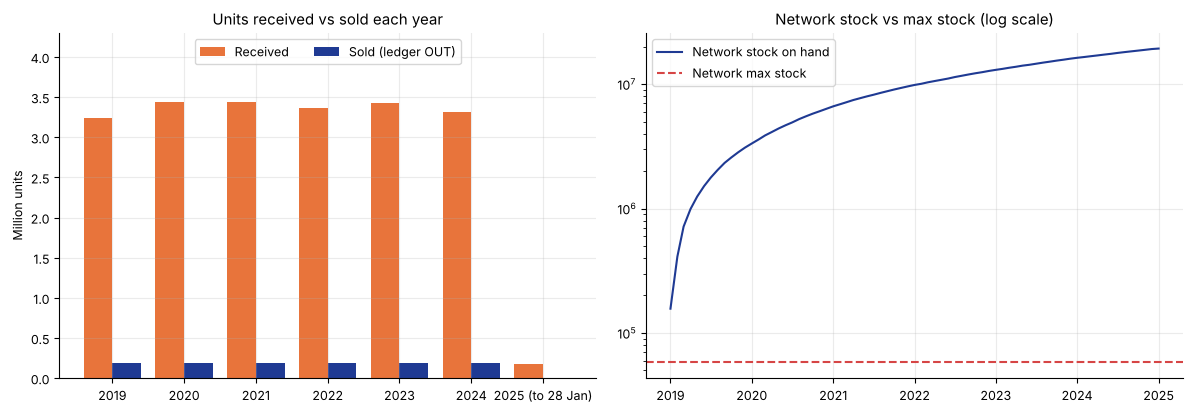

In [16]:
mth = led.groupby(led.movement_date.dt.to_period("M")).implied_signed_quantity.sum().cumsum() + inv.opening_stock.sum()
mth.index = mth.index.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(yr)); ax[0].bar(x - .2, yr.received / 1e6, .4, color=ORANGE, label="Received"); ax[0].bar(x + .2, yr.sold_out / 1e6, .4, color=BLUE, label="Sold (ledger OUT)")
ax[0].set_xticks(x); ax[0].set_xticklabels([str(i) if i < 2025 else "2025 (to 28 Jan)" for i in yr.index]); ax[0].set_ylabel("Million units")
ax[0].set_ylim(0, 4.3); ax[0].legend(ncol=2, loc="upper center"); ax[0].set_title("Units received vs sold each year")
ax[1].plot(mth.index, mth.values, color=BLUE, label="Network stock on hand"); ax[1].axhline(pos.max_stock.sum(), color=RED, ls="--", label="Network max stock")
ax[1].set_yscale("log"); ax[1].set_title("Network stock vs max stock (log scale)"); ax[1].legend()
save("04_replenishment")

## 6. Right-sizing view
How long the stock would last if purchasing stopped, and how much of it should be sold down to bring each position back to its max stock.

In [17]:
prod = pos.groupby(["product_id", "product_name", "category"], as_index=False).agg(
    current_stock=("current_stock", "sum"), max_stock=("max_stock", "sum"), units_L12M=("units_L12M", "sum"),
    stock_value=("stock_value", "sum"), excess_units=("excess_units", "sum"), excess_value=("excess_value", "sum"))
prod["stock_to_max"] = prod.current_stock / prod.max_stock
prod["years_of_supply"] = prod.current_stock / prod.units_L12M
prod = prod.merge(by_prod[["product_id", "avg_age_days", "pct_over_2y"]], on="product_id")
prod["stock_value_cr"] = prod.stock_value / 1e7; prod["excess_value_cr"] = prod.excess_value / 1e7
print(f"Products: stock to max {prod.stock_to_max.min():.0f}x to {prod.stock_to_max.max():.0f}x; years of supply {prod.years_of_supply.min():.0f} to {prod.years_of_supply.max():.0f}")
print(f"Five largest products by excess value hold {prod.nlargest(5, 'excess_value').excess_value.sum()/prod.excess_value.sum()*100:.0f}% of all excess value")
prod.sort_values("excess_value", ascending=False)[["product_name", "stock_value_cr", "stock_to_max", "years_of_supply", "avg_age_days", "pct_over_2y"]].round(
    {"stock_value_cr": 0, "stock_to_max": 0, "years_of_supply": 0, "avg_age_days": 0, "pct_over_2y": 0}).head(8)

Products: stock to max 260x to 434x; years of supply 85 to 108
Five largest products by excess value hold 60% of all excess value

,product_name,stock_value_cr,stock_to_max,years_of_supply,avg_age_days,pct_over_2y
14,Engine Block EB-600,6041.0,345.0,100.0,1050.0,65.0
13,Transmission Assembly TA-800,4532.0,345.0,98.0,1066.0,66.0
20,Boom Cylinder BC-400,2245.0,291.0,93.0,1023.0,64.0
3,Track Chain TC-45,2076.0,345.0,96.0,1036.0,64.0
18,Swing Motor SWM-350,1941.0,336.0,102.0,1053.0,66.0
9,Turbocharger TB-900,1911.0,434.0,103.0,1052.0,66.0
10,Hydraulic Cylinder HC-200,1398.0,329.0,95.0,1049.0,65.0
0,Hydraulic Pump HP-300,1220.0,274.0,98.0,1043.0,64.0


## 7. Export results

In [18]:
pos.drop(columns=["criticality_level"]).to_csv(OUT_DIR / "position_stock_health.csv", index=False)
prod.to_csv(OUT_DIR / "product_stock_health.csv", index=False)
ag.reset_index().to_csv(OUT_DIR / "ageing_by_bucket.csv", index=False)
by_branch_pct.round(2).reset_index().to_csv(OUT_DIR / "ageing_by_branch_pct.csv", index=False)
yr.reset_index().rename(columns={"movement_date": "year"}).to_csv(OUT_DIR / "replenishment_by_year.csv", index=False)
low_ev.to_csv(OUT_DIR / "historical_low_stock_events.csv", index=False)
print(sorted(p.name for p in OUT_DIR.glob("*.csv")), len(list((OUT_DIR / "charts").glob("*.png"))), "charts")

['ageing_by_branch_pct.csv', 'ageing_by_bucket.csv', 'historical_low_stock_events.csv', 'position_stock_health.csv', 'product_stock_health.csv', 'replenishment_by_year.csv'] 4 charts